In [2]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import pandas as pd
import re
import os
%matplotlib inline

# ── PATHS ──────────────────────────────────────────────────────────────────────
BASE = "/home/ottena/mags_project/vfdb_analysis"
STRICT_OUT = f"{BASE}/output_strict"
LABEL_FILE = "/home/ottena/mags_project/pankmer_analysis/label_lookup_v3.csv"

# ── LOAD LABELS ────────────────────────────────────────────────────────────────
labels = pd.read_csv(LABEL_FILE)

def strip_ext(name):
    return re.sub(r"\.(fna|fasta|fa)$", "", str(name), flags=re.IGNORECASE)

labels["original_stripped"] = labels["original_name"].apply(strip_ext)
name_map = dict(zip(labels["original_stripped"], labels["plot_label"]))

def rename_genome(name):
    key = strip_ext(str(name))
    return name_map.get(key, name)

# ── LOAD AND COMBINE ALL STRICT RESULTS ───────────────────────────────────────
print("Loading strict VFDB results...")
all_data = []
for f in os.listdir(STRICT_OUT):
    if f.endswith("_vfdb_strict.tsv"):
        genome = f.replace("_vfdb_strict.tsv", "")
        df = pd.read_csv(os.path.join(STRICT_OUT, f), sep="\t", header=None,
                 names=["qseqid","sseqid","pident","length","mismatch",
                        "gapopen","qstart","qend","sstart","send",
                        "evalue","bitscore","stitle"],
                 encoding="latin-1")
        df["genome"] = genome
        all_data.append(df)

combined = pd.concat(all_data, ignore_index=True)

# ── EXTRACT VF CATEGORY ────────────────────────────────────────────────────────
def extract_category(stitle):
    match = re.search(r'\) - (.+?) \(VFC', stitle)
    if match:
        return match.group(1).strip()
    return "Unknown"

def extract_vf_name(stitle):
    match = re.search(r'\((\w+)\) (.+?) \[', stitle)
    if match:
        return match.group(2).strip()
    match2 = re.search(r'\[(.+?) \(VF', stitle)
    if match2:
        return match2.group(1).strip()
    return stitle[:30]

combined["category"] = combined["stitle"].apply(extract_category)
combined["vf_name"] = combined["stitle"].apply(extract_vf_name)
combined["label"] = combined["genome"].apply(rename_genome)

# Assign host type
def get_host(label):
    label_lower = label.lower()
    if "pig" in label_lower or "swine" in label_lower:
        return "Pig"
    elif "cow" in label_lower or "rumen" in label_lower or "bostaurus" in label_lower or "holstein" in label_lower:
        return "Cow"
    elif "gallus" in label_lower or "chicken" in label_lower or "caecal" in label_lower:
        return "Chicken"
    elif "human" in label_lower or "dental" in label_lower or "feces" in label_lower:
        return "Human"
    elif "spoiled" in label_lower or "beer" in label_lower:
        return "Other"
    elif "masinjere" in label_lower or "masenjere" in label_lower:
        return "MAG_Masinjere"
    elif "limera" in label_lower:
        return "MAG_Limera"
    else:
        return "Other"

combined["host"] = combined["label"].apply(get_host)

print(f"Total hits: {len(combined)}")
print(f"\nVF Categories found:")
print(combined["category"].value_counts())

Loading strict VFDB results...
Total hits: 2046

VF Categories found:
category
Immune modulation               954
Nutritional/Metabolic factor    396
Adherence                       253
Enzyme                          149
Stress survival                 127
Effector delivery system         84
Motility                         56
Exotoxin                         21
Invasion                          4
Regulation                        2
Name: count, dtype: int64


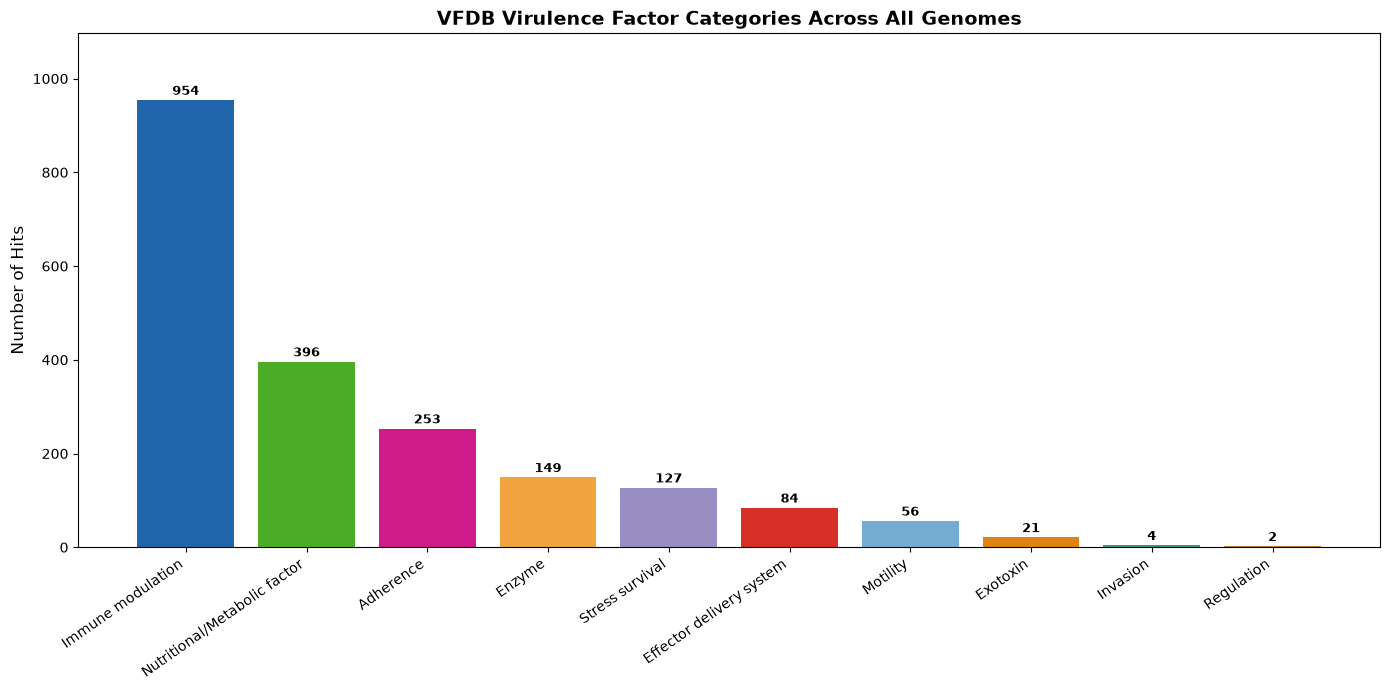

Graph 1 done!


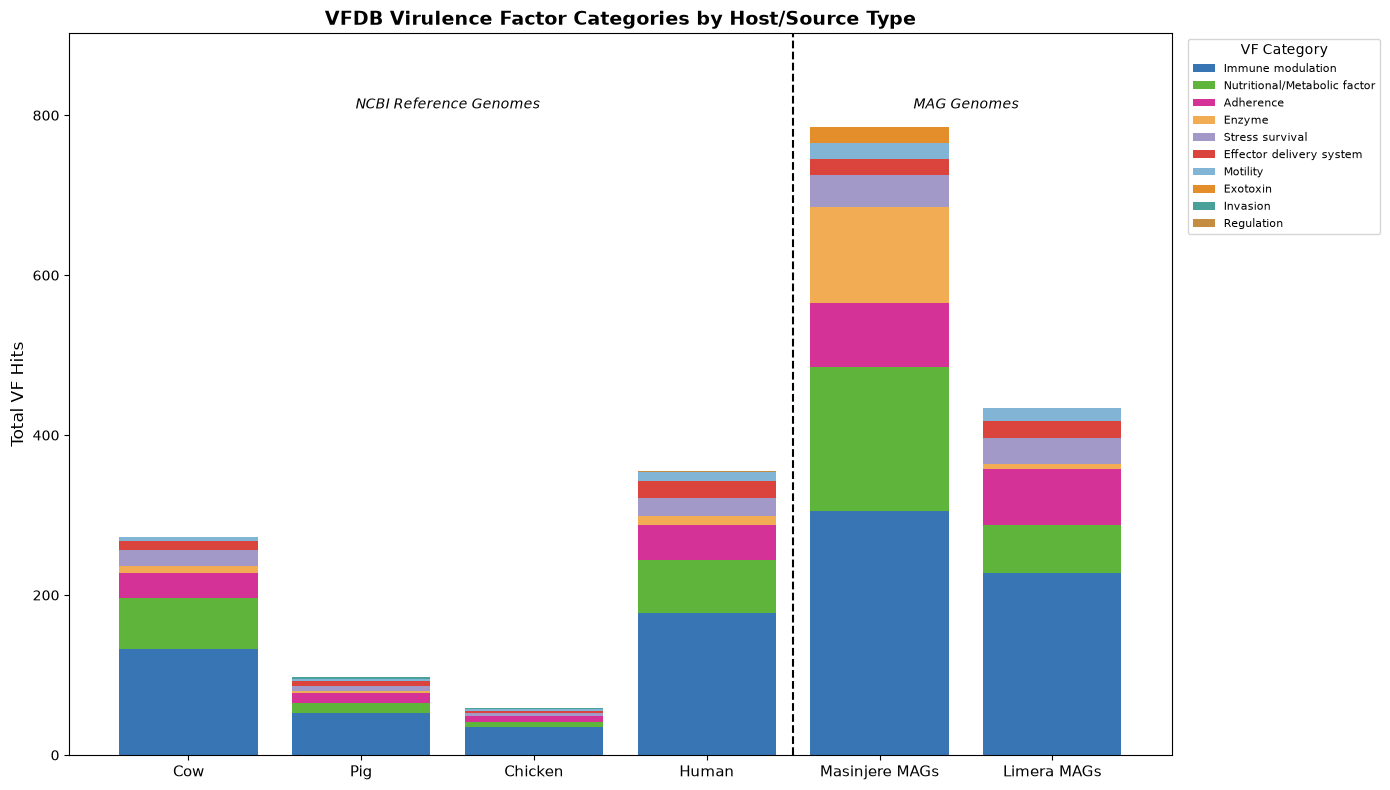

Graph 2 done!


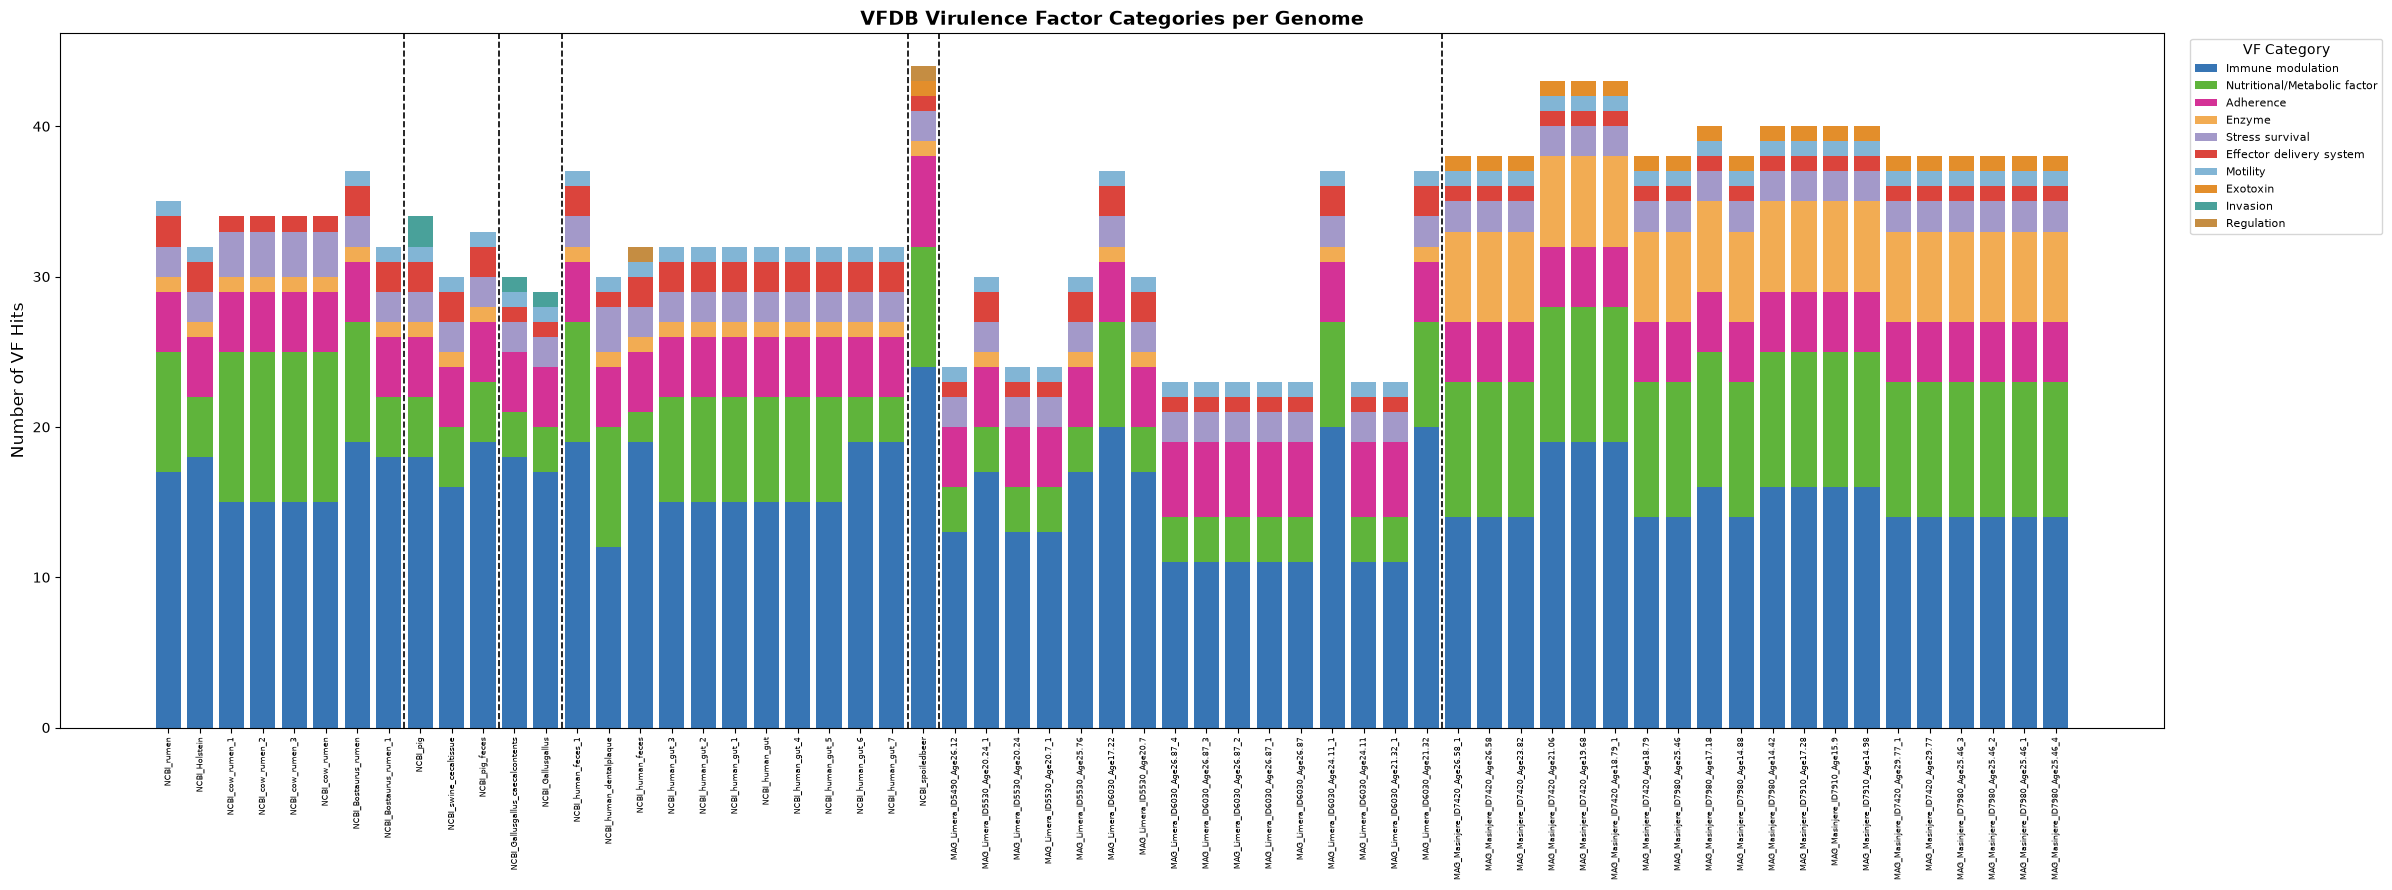

Graph 3 done!

All figures saved!


In [3]:
# ── COLOR PALETTE FOR CATEGORIES ──────────────────────────────────────────────
cat_colors = {
    "Immune modulation": "#2166ac",
    "Nutritional/Metabolic factor": "#4dac26",
    "Adherence": "#d01c8b",
    "Enzyme": "#f1a340",
    "Stress survival": "#998ec3",
    "Effector delivery system": "#d73027",
    "Motility": "#74add1",
    "Exotoxin": "#e08214",
    "Invasion": "#35978f",
    "Regulation": "#bf812d",
    "Unknown": "#999999"
}

host_order = ["Cow", "Pig", "Chicken", "Human", "MAG_Masinjere", "MAG_Limera"]

# ── GRAPH 1: Overall VF category bar chart ─────────────────────────────────────
cat_counts = combined["category"].value_counts().reset_index()
cat_counts.columns = ["category", "count"]

fig, ax = plt.subplots(figsize=(14, 7))
bars = ax.bar(range(len(cat_counts)), cat_counts["count"],
              color=[cat_colors.get(c, "#999999") for c in cat_counts["category"]])

ax.set_xticks(range(len(cat_counts)))
ax.set_xticklabels(cat_counts["category"], rotation=35, ha="right", fontsize=10)
ax.set_ylabel("Number of Hits", fontsize=12)
ax.set_title("VFDB Virulence Factor Categories Across All Genomes", fontsize=14, fontweight="bold")
ax.set_ylim(0, cat_counts["count"].max() * 1.15)

for bar, (_, row) in zip(bars, cat_counts.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 5,
            str(int(row["count"])),
            ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig(f"{BASE}/VFDB_category_overall.pdf", bbox_inches="tight")
plt.show()
print("Graph 1 done!")

# ── GRAPH 2: Stacked bar — VF categories by host type ─────────────────────────
host_cat = combined.groupby(["host", "category"]).size().reset_index(name="count")
host_cat = host_cat[host_cat["host"].isin(host_order)]

categories = cat_counts["category"].tolist()

fig, ax = plt.subplots(figsize=(14, 8))
bottom = [0] * len(host_order)

for category in categories:
    data = host_cat[host_cat["category"] == category].set_index("host")
    values = [data.loc[h, "count"] if h in data.index else 0 for h in host_order]
    ax.bar(range(len(host_order)), values, bottom=bottom,
           label=category, color=cat_colors.get(category, "#999999"), alpha=0.9)
    bottom = [b + v for b, v in zip(bottom, values)]

ax.axvline(x=3.5, color="black", linestyle="--", linewidth=1.5)
ax.text(1.5, max(bottom) * 1.03, "NCBI Reference Genomes",
        ha="center", fontsize=10, fontstyle="italic")
ax.text(4.5, max(bottom) * 1.03, "MAG Genomes",
        ha="center", fontsize=10, fontstyle="italic")

ax.set_xticks(range(len(host_order)))
ax.set_xticklabels(["Cow", "Pig", "Chicken", "Human", "Masinjere MAGs", "Limera MAGs"],
                   fontsize=11)
ax.set_ylabel("Total VF Hits", fontsize=12)
ax.set_title("VFDB Virulence Factor Categories by Host/Source Type", fontsize=14, fontweight="bold")
ax.set_ylim(0, max(bottom) * 1.15)
ax.legend(title="VF Category", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(f"{BASE}/VFDB_category_by_host.pdf", bbox_inches="tight")
plt.show()
print("Graph 2 done!")

# ── GRAPH 3: Stacked bar — VF categories per genome ───────────────────────────
genome_cat = combined.groupby(["label", "category"]).size().reset_index(name="count")

# Sort by host type
genome_totals = genome_cat.groupby("label")["count"].sum().reset_index()
genome_totals["host"] = genome_totals["label"].apply(get_host)
genome_totals["host_order"] = genome_totals["host"].map({
    "Cow": 0, "Pig": 1, "Chicken": 2, "Human": 3,
    "Other": 4, "MAG_Limera": 5, "MAG_Masinjere": 6
})
genome_totals = genome_totals.sort_values("host_order")
genome_order = genome_totals["label"].tolist()

fig, ax = plt.subplots(figsize=(24, 9))
bottom = pd.Series([0.0] * len(genome_order), index=genome_order)

for category in categories:
    values = []
    for genome in genome_order:
        subset = genome_cat[(genome_cat["label"] == genome) & (genome_cat["category"] == category)]
        values.append(subset["count"].sum() if len(subset) > 0 else 0)
    ax.bar(range(len(genome_order)), values, bottom=bottom.values,
           label=category, color=cat_colors.get(category, "#999999"), alpha=0.9)
    bottom += pd.Series(values, index=genome_order)

# Dividing lines between host groups
prev_host = genome_totals.iloc[0]["host"]
for i, row in enumerate(genome_totals.itertuples()):
    if row.host != prev_host:
        ax.axvline(x=i - 0.5, color="black", linestyle="--", linewidth=1.2)
        prev_host = row.host

ax.set_xticks(range(len(genome_order)))
ax.set_xticklabels(genome_order, rotation=90, fontsize=5.5)
ax.set_ylabel("Number of VF Hits", fontsize=12)
ax.set_title("VFDB Virulence Factor Categories per Genome", fontsize=14, fontweight="bold")
ax.legend(title="VF Category", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(f"{BASE}/VFDB_category_per_genome.pdf", bbox_inches="tight")
plt.show()
print("Graph 3 done!")

print("\nAll figures saved!")